In [1]:
from google.colab import files
uploaded = files.upload()


Saving train.csv to train.csv
Saving test (1).csv to test (1).csv
Saving gender_submission.csv to gender_submission.csv
Saving README (1).md to README (1).md


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test (1).csv")
gender = pd.read_csv("gender_submission.csv")

print("All datasets loaded successfully!")

print("Train Shape:", train.shape)
print("Test Shape:", test.shape)
print("Gender Submission Shape:", gender.shape)

All datasets loaded successfully!
Train Shape: (891, 12)
Test Shape: (418, 11)
Gender Submission Shape: (418, 2)


In [4]:
print("First 5 Rows:")
display(train.head())

print("\nDataset Information:")
train.info()

print("\nStatistical Summary:")
display(train.describe())

First 5 Rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
print("Missing Values in Training Data:")
print(train.isnull().sum())

print("\nMissing Values in Testing Data:")
print(test.isnull().sum())

Missing Values in Training Data:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing Values in Testing Data:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


In [6]:
print("Duplicate Rows:", train.duplicated().sum())

print("Duplicate Passenger IDs:", train["PassengerId"].duplicated().sum())

Duplicate Rows: 0
Duplicate Passenger IDs: 0


In [7]:
train_cleaned = train.copy()
test_cleaned = test.copy()

# Fill missing Age values
train_cleaned["Age"] = train_cleaned["Age"].fillna(
    train_cleaned["Age"].median()
)

test_cleaned["Age"] = test_cleaned["Age"].fillna(
    test_cleaned["Age"].median()
)

# Fill missing Embarked values
train_cleaned["Embarked"] = train_cleaned["Embarked"].fillna(
    train_cleaned["Embarked"].mode()[0]
)

test_cleaned["Embarked"] = test_cleaned["Embarked"].fillna(
    test_cleaned["Embarked"].mode()[0]
)

# Fill missing Fare in test data
test_cleaned["Fare"] = test_cleaned["Fare"].fillna(
    test_cleaned["Fare"].median()
)

# Drop Cabin because it has many missing values
train_cleaned.drop(columns=["Cabin"], inplace=True)
test_cleaned.drop(columns=["Cabin"], inplace=True)

print("Data Cleaning Completed!")

Data Cleaning Completed!


In [8]:
print("Train Missing Values:")
print(train_cleaned.isnull().sum())

print("\nTest Missing Values:")
print(test_cleaned.isnull().sum())

Train Missing Values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Test Missing Values:
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


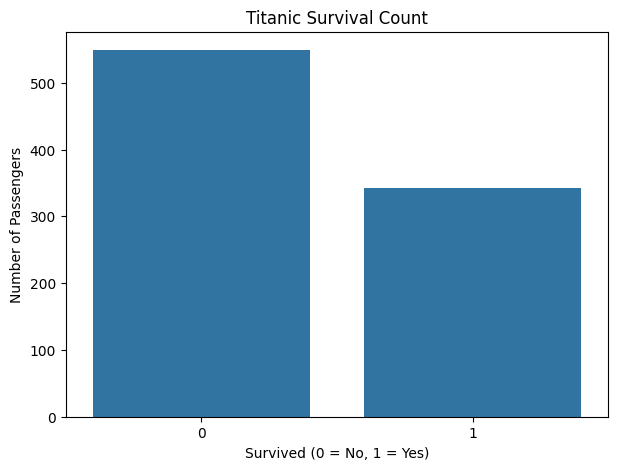

In [9]:
plt.figure(figsize=(7,5))

sns.countplot(data=train_cleaned, x="Survived")

plt.title("Titanic Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

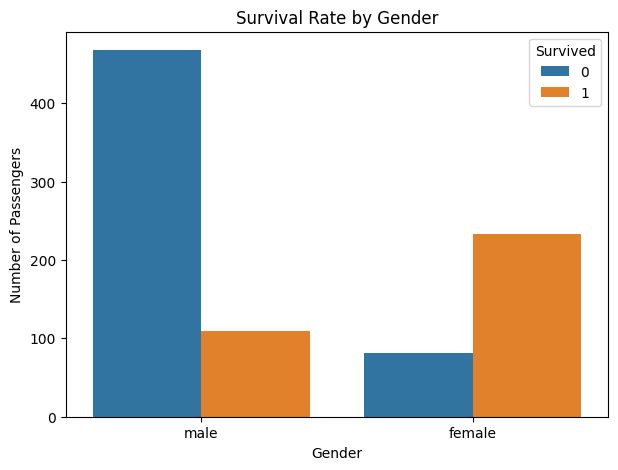

In [10]:
plt.figure(figsize=(7,5))

sns.countplot(data=train_cleaned, x="Sex", hue="Survived")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

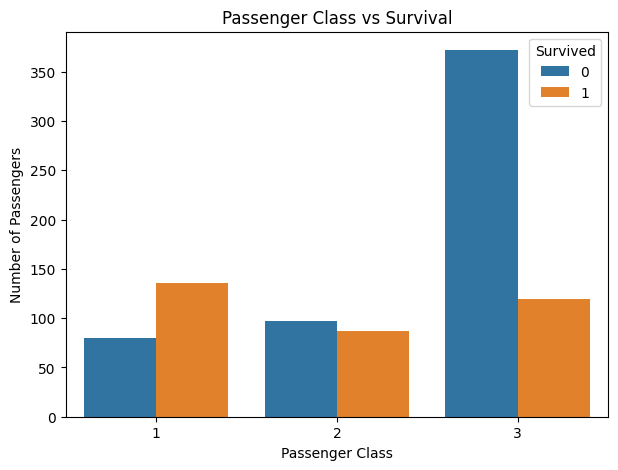

In [11]:
plt.figure(figsize=(7,5))

sns.countplot(data=train_cleaned, x="Pclass", hue="Survived")

plt.title("Passenger Class vs Survival")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

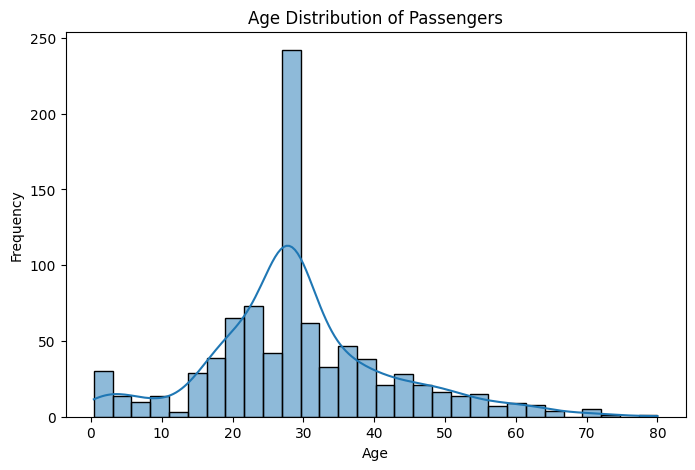

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(data=train_cleaned, x="Age", bins=30, kde=True)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

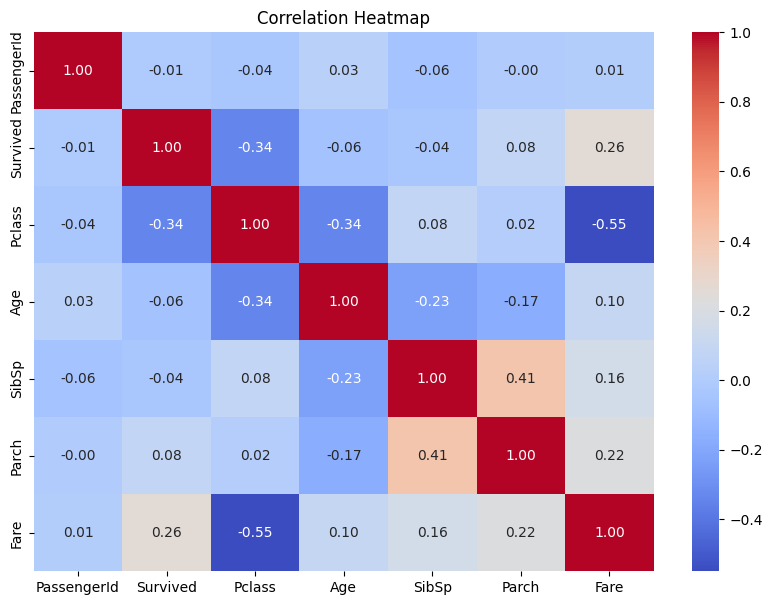

In [13]:
plt.figure(figsize=(10,7))

sns.heatmap(
    train_cleaned.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [14]:
train_cleaned.to_csv("cleaned_train.csv", index=False)
test_cleaned.to_csv("cleaned_test.csv", index=False)

print("Cleaned datasets saved successfully!")

Cleaned datasets saved successfully!


In [15]:
from google.colab import files

files.download("cleaned_train.csv")
files.download("cleaned_test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

CONCLUSION:

1. The Titanic dataset contains passenger information.
2. Data cleaning helped handle missing values.
3. Survival patterns were analysed using gender and passenger class.
4. Age distribution was studied using a histogram.
5. Correlation analysis helped understand relationships between numerical variables.

This project helped me understand data cleaning and exploratory data analysis using Python.